#### Requirements

In [1]:
import pandas as pd
import numpy as np

import sys
sys.path.append("../..")

from src.backtester import calculate_return, backtester
from src.strategies import run_momentum_strategy
from src.summary import summary

In [2]:
df = pd.read_csv("../../data/spy_daily.csv")
prices = df["Adj Close"]
returns = calculate_return(prices)
lookback = 252

In [3]:
momentum_df, momentum_results = run_momentum_strategy(prices, returns, lookback, 0.001)

#### Elementary Random Benchmark

In [4]:
def generate_random_signal(prices, lookback):

    random_signal = [np.nan] * lookback

    choice = np.random.choice([0,1], size = len(prices) - lookback)

    random_signal = random_signal + choice.tolist()

    return random_signal

In [5]:
df["Random Signal"] = generate_random_signal(prices, lookback)
random_signal = df["Random Signal"]

In [6]:
random_df, random_result = backtester(returns, random_signal, 0.001)
pd.Series(random_result)

total_return           -0.941120
cagr                   -0.104599
annual_volatility       0.129943
annual_sharpe          -0.784845
max_drawdown           -0.951760
calmar                 -0.109901
time_invested           0.496285
trades               3152.000000
dtype: float64

In [7]:
def run_simulation(n):

    simulation_result = []

    for i in range(n):

        random_signal = generate_random_signal(prices, lookback)
        _, random_result = backtester(returns, random_signal, 0.001)

        simulation_result.append(random_result)

    return simulation_result



In [8]:
np.random.seed(44)

simulation_output = run_simulation(1000)
simulation_df = pd.DataFrame(simulation_output)
simulation_df

,total_return,cagr,annual_volatility,annual_sharpe,max_drawdown,calmar,time_invested,trades
0,-0.900851,-0.086211,0.134085,-0.605255,-0.903483,-0.095421,0.493653,3279
1,-0.923670,-0.095487,0.130780,-0.701597,-0.931631,-0.102495,0.491486,3311
2,-0.940493,-0.104230,0.140298,-0.714127,-0.952875,-0.109384,0.491641,3253
3,-0.881654,-0.079880,0.139962,-0.524890,-0.900784,-0.088679,0.503715,3202
4,-0.817663,-0.064234,0.138258,-0.411022,-0.874031,-0.073492,0.503560,3206
...,...,...,...,...,...,...,...,...
995,-0.915347,-0.091828,0.136861,-0.635218,-0.936214,-0.098084,0.497059,3192
996,-0.872644,-0.077243,0.134459,-0.530324,-0.891661,-0.086628,0.503406,3232
997,-0.947506,-0.108600,0.136947,-0.770418,-0.952301,-0.114040,0.504180,3169
998,-0.840393,-0.069082,0.135575,-0.459956,-0.855507,-0.080749,0.496904,3219


Sharpe Average: -0.5450
Sharpe Median:  -0.5475
Largest Sharpe: -0.1164
Average No. of Trades: 3227.0240
Average Time Invested: 0.5004
Empirical p-value: 0.001


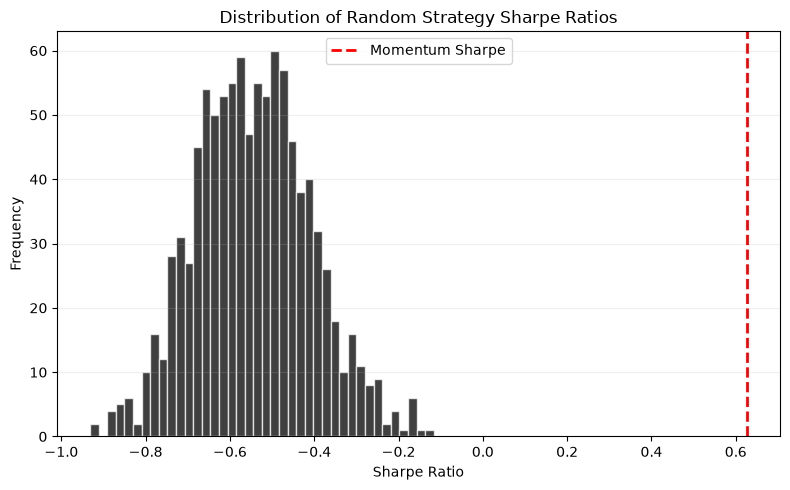

In [9]:
summary(simulation_df, momentum_results, "Distribution of Random Strategy Sharpe Ratios")